# 03 — Proposed ResNet-18 with staged fine-tuning

The proposed model is an ImageNet-pretrained ResNet-18 with dropout, mild X-ray-safe augmentation, weighted cross-entropy, label smoothing, and three fine-tuning stages: head, layer4, then full network with discriminative layer learning rates.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: C:\Users\DAR\Desktop\Pneumonia_classification\p06-pneumonia-limited-data


In [2]:
from src.utils import load_config
cfg = load_config("configs/proposed.yaml")
for stage in cfg["training"]["stages"]:
    print(stage)

{'name': 'head', 'epochs': 3, 'lr': 0.001, 'unfreeze': ['fc'], 'scheduler': 'cosine', 'weight_decay': 0.0}
{'name': 'layer4', 'epochs': 4, 'lr': 0.0001, 'unfreeze': ['layer4', 'fc'], 'scheduler': 'cosine', 'weight_decay': 0.0001}
{'name': 'full', 'epochs': 5, 'lr': 1e-05, 'unfreeze': 'all', 'scheduler': 'cosine', 'weight_decay': 0.0001, 'layer_lr_mult': {'conv1': 0.1, 'bn1': 0.1, 'layer1': 0.1, 'layer2': 0.3, 'layer3': 0.5, 'layer4': 0.8, 'fc': 1.0}}


Training commands (about 21–31 minutes per seed on the CPU host):

```powershell
python -m src.train --config configs/proposed.yaml --seed 42
python -m src.evaluate --checkpoint checkpoints/proposed_seed42.pt --splits val test
```

All reported seeds use batch size 16.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

hist = pd.read_csv("results/proposed/seed42/history.csv")
hist[["epoch", "stage", "train_loss", "val_loss", "val_macro_f1", "val_macro_auroc"]].tail(12)

Out[0]: 
    epoch   stage  train_loss  val_loss  val_macro_f1  val_macro_auroc
0       1    head    0.973103  0.844298      0.637399         0.852117
1       2    head    0.833584  0.772217      0.731896         0.872722
2       3    head    0.797194  0.790485      0.722519         0.872856
3       4  layer4    0.758573  0.741262      0.749362         0.896681
4       5  layer4    0.672865  0.709670      0.789567         0.909002
5       6  layer4    0.640001  0.712953      0.802316         0.910109
6       7  layer4    0.586918  0.689698      0.803290         0.916043
7       8    full    0.595749  0.704106      0.780360         0.915233
8       9    full    0.558761  0.690789      0.794027         0.915444
9      10    full    0.566664  0.688723      0.805084         0.915409
10     11    full    0.554504  0.685904      0.801675         0.916489
11     12    full    0.560178  0.689595      0.803157         0.915657


,epoch,stage,train_loss,val_loss,val_macro_f1,val_macro_auroc
0,1,head,0.973103,0.844298,0.637399,0.852117
1,2,head,0.833584,0.772217,0.731896,0.872722
2,3,head,0.797194,0.790485,0.722519,0.872856
3,4,layer4,0.758573,0.741262,0.749362,0.896681
4,5,layer4,0.672865,0.709670,0.789567,0.909002
5,6,layer4,0.640001,0.712953,0.802316,0.910109
6,7,layer4,0.586918,0.689698,0.803290,0.916043
7,8,full,0.595749,0.704106,0.780360,0.915233
8,9,full,0.558761,0.690789,0.794027,0.915444
9,10,full,0.566664,0.688723,0.805084,0.915409


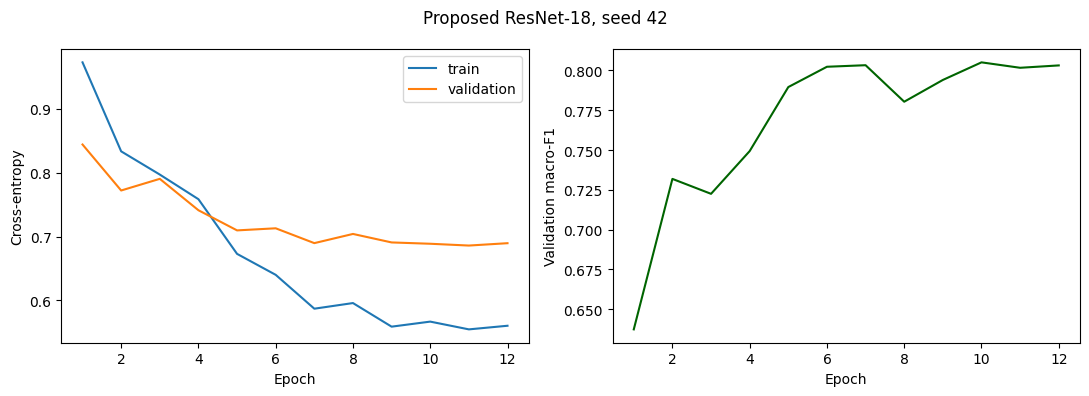

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(hist.epoch, hist.train_loss, label="train")
axes[0].plot(hist.epoch, hist.val_loss, label="validation")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy"); axes[0].legend()
axes[1].plot(hist.epoch, hist.val_macro_f1, color="darkgreen")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Validation macro-F1")
fig.suptitle("Proposed ResNet-18, seed 42")
fig.tight_layout()
plt.show()

In [5]:
import json
for seed in (42, 43, 44):
    m = json.load(open(f"results/proposed/seed{seed}/metrics_test.json"))
    print(seed, {k: round(m[k], 4) for k in ("accuracy", "balanced_accuracy", "macro_f1", "macro_auroc", "ece")})

42 {'accuracy': 0.8365, 'balanced_accuracy': 0.8317, 'macro_f1': 0.8273, 'macro_auroc': 0.956, 'ece': 0.102}
43 {'accuracy': 0.8446, 'balanced_accuracy': 0.8362, 'macro_f1': 0.8343, 'macro_auroc': 0.9568, 'ece': 0.0989}
44 {'accuracy': 0.8526, 'balanced_accuracy': 0.8452, 'macro_f1': 0.8426, 'macro_auroc': 0.9475, 'ece': 0.0996}


Test macro-F1: 0.8273, 0.8343, 0.8426 for seeds 42, 43, 44. Mean ± std: 0.8347 ± 0.0077. The paired bootstrap difference versus the baseline is positive for all three seeds.